In [1]:
# Install required libraries
!pip install opencv-python==5.0.0.* opencv-contrib-python==5.0.0.* ultralytics matplotlib numpy

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV Version:", cv2.__version__)

OpenCV Version: 5.0.0


In [3]:
import os

print(os.listdir("data/images"))

['cars.jpeg', 'cr.jpg', 'GRAY_spidy.jpg', 'loki.jpg', 'luffy.png', 'objs.png', 'powerrangers.jpeg', 'tony.jpg', 'walter.jpg', 'yash.jpeg', 'yash2.jpeg']


# Task 1

## 1.1 Load Image

Grayscale Shape: (1080, 1919)
Grayscale Data Type: uint8
Color Shape: (2160, 3840, 3)
Color Data Type: uint8


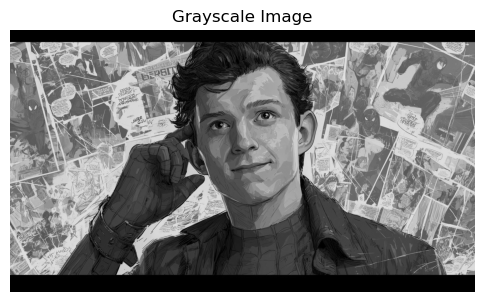

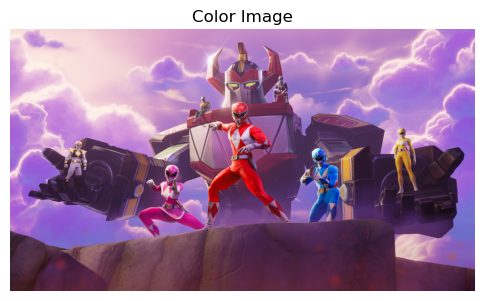

In [4]:
# Load grayscale image
gray_img = cv2.imread("data/images/GRAY_spidy.jpg", cv2.IMREAD_GRAYSCALE)

# Load color image
color_img = cv2.imread("data/images/powerrangers.jpeg")

print("Grayscale Shape:", gray_img.shape)
print("Grayscale Data Type:", gray_img.dtype)

print("Color Shape:", color_img.shape)
print("Color Data Type:", color_img.dtype)

def show(img, title="Image"):
    plt.figure(figsize=(6, 4))
    
    if len(img.shape) == 3:
        # Convert BGR to RGB
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.imshow(img_rgb)
    else:
        plt.imshow(img, cmap="gray")
    
    plt.title(title)
    plt.axis("off")
    plt.show()

show(gray_img, "Grayscale Image")
show(color_img, "Color Image")

## 1.2 Binarize a Test Image

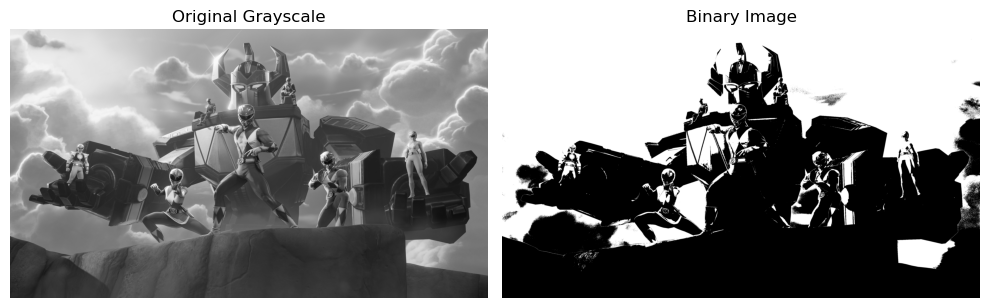

In [5]:
# Convert color image to grayscale
gray = cv2.cvtColor(color_img, cv2.COLOR_BGR2GRAY)

# Apply binary threshold
_, binary = cv2.threshold(
    gray,
    127,
    255,
    cv2.THRESH_BINARY
)

# Display grayscale and binary images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.tight_layout()
plt.show()

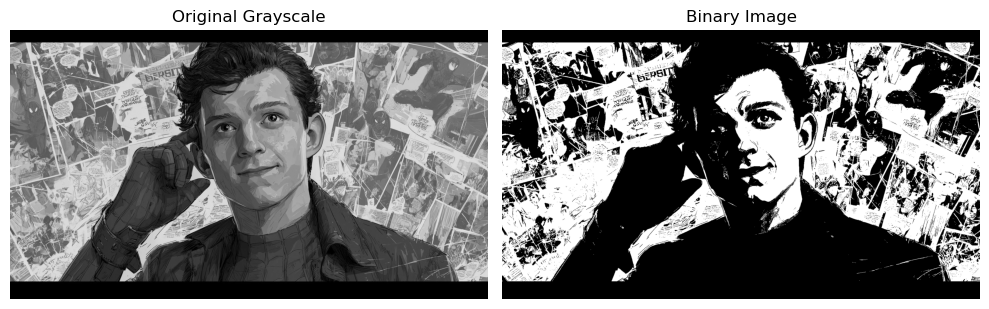

In [6]:
# Apply binary threshold directly
_, binary = cv2.threshold(
    gray_img,
    127,
    255,
    cv2.THRESH_BINARY
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray_img, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.tight_layout()
plt.show()

## 1.3 Apply the Four Morphological Operations

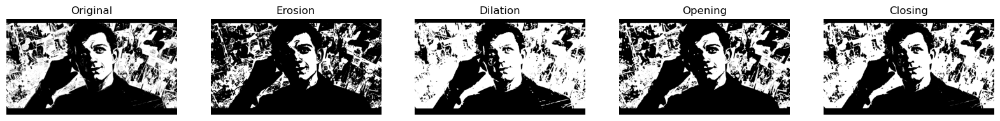

In [7]:
kernel=np.ones((5,5),np.uint8)
erosion=cv2.erode(binary,kernel)
dilation=cv2.dilate(binary,kernel)
opening=cv2.morphologyEx(binary,cv2.MORPH_OPEN,kernel)
closing=cv2.morphologyEx(binary,cv2.MORPH_CLOSE,kernel)

plt.figure(figsize=(20,4))
for i,(img,title) in enumerate(zip([binary,erosion,dilation,opening,closing],
                                   ["Original","Erosion","Dilation","Opening","Closing"]),1):
    plt.subplot(1,5,i); plt.imshow(img,cmap="gray"); plt.title(title); plt.axis("off")
plt.show()

## 1.4 Kernel Shape & Size Comparison

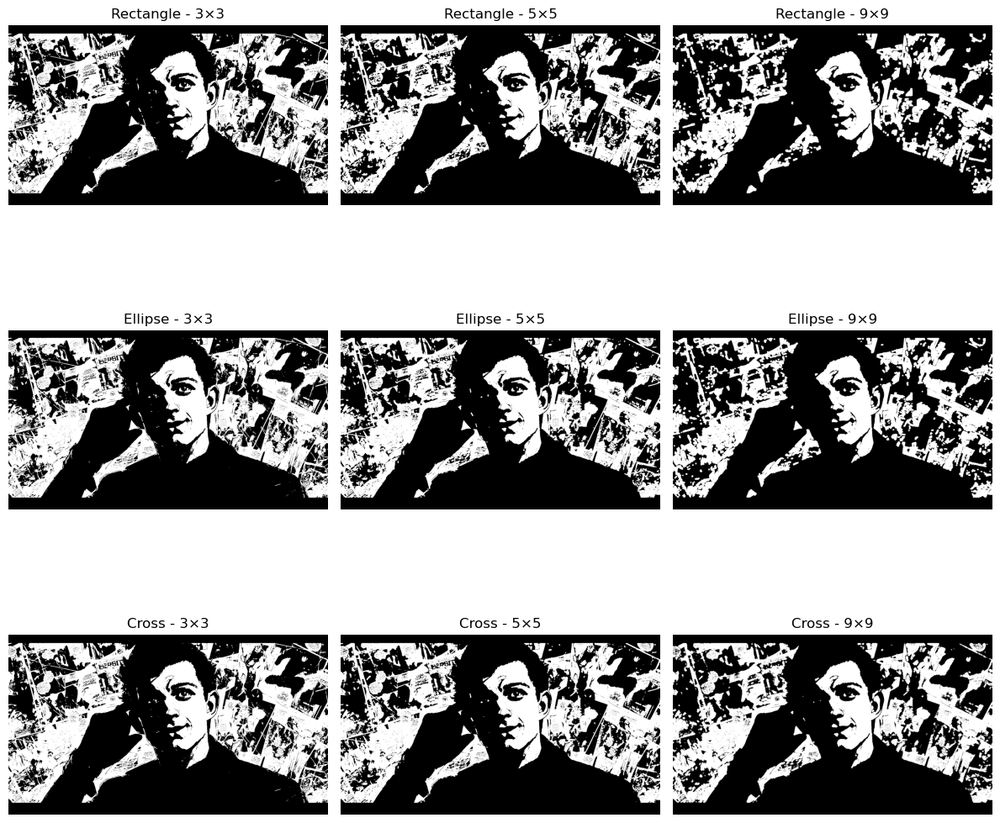

In [8]:
# Define kernel shapes
shapes = {
    "Rectangle": cv2.MORPH_RECT,
    "Ellipse": cv2.MORPH_ELLIPSE,
    "Cross": cv2.MORPH_CROSS
}

# Define kernel sizes
sizes = [3, 5, 9]

# Create 3×3 comparison grid
plt.figure(figsize=(12, 12))

plot_index = 1

for shape_name, shape_type in shapes.items():
    for size in sizes:

        # Create structuring element
        kernel = cv2.getStructuringElement(
            shape_type,
            (size, size)
        )

        # Apply morphological opening
        result = cv2.morphologyEx(
            binary,
            cv2.MORPH_OPEN,
            kernel
        )

        # Display result
        plt.subplot(3, 3, plot_index)
        plt.imshow(result, cmap="gray")
        plt.title(f"{shape_name} - {size}×{size}")
        plt.axis("off")

        plot_index += 1

plt.tight_layout()
plt.show()

## 1.5 — WHY Morphology Works



### Erosion:- Shrinks white regions and removes small bright noise.
### Dilation:- Grows white regions and fills small dark gaps.
### Opening:- Erosion → Dilation; removes small noise.
### Closing:- Dilation → Erosion; fills small holes and gaps.
### Real-World Use:- Morphology cleans noisy images before face or object detection.

# Task 2

## Task 2.1 — Bitwise AND / OR / XOR / NOT


In [9]:
# Create two black masks
mask1 = np.zeros((400, 400), dtype=np.uint8)
cv2.circle(mask1, (200, 200), 100, 255, -1)

mask2 = np.zeros((400, 400), dtype=np.uint8)
cv2.rectangle(mask2, (100, 100), (300, 300), 255, -1)

# Apply bitwise operations
bitwise_and = cv2.bitwise_and(mask1, mask2)
bitwise_or = cv2.bitwise_or(mask1, mask2)
bitwise_xor = cv2.bitwise_xor(mask1, mask2)
bitwise_not = cv2.bitwise_not(mask1)

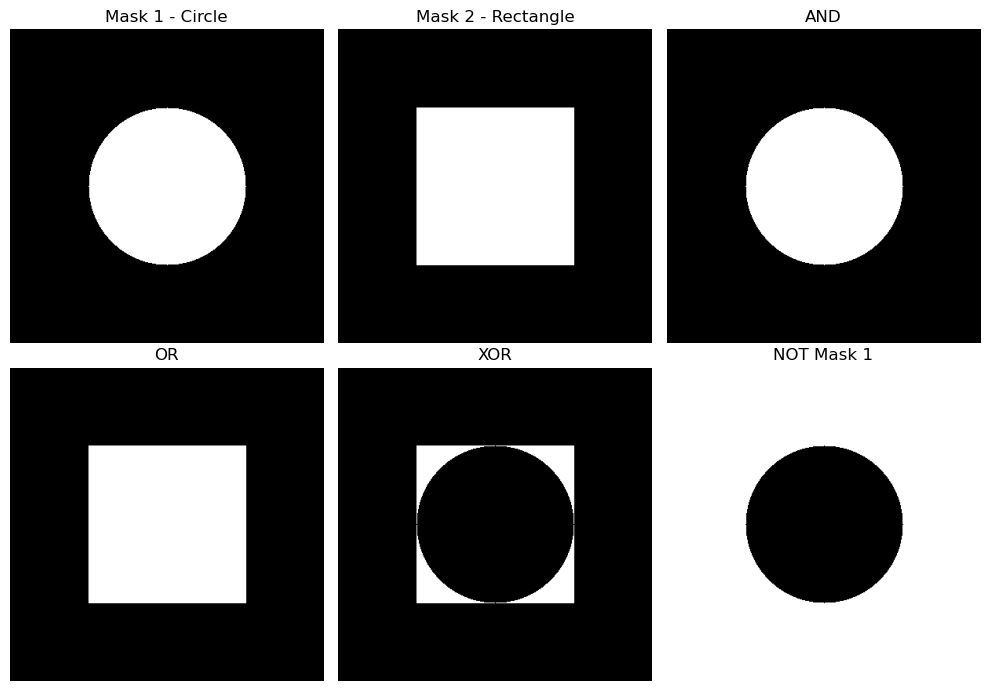

In [10]:
plt.figure(figsize=(10, 7))

images = [
    mask1,
    mask2,
    bitwise_and,
    bitwise_or,
    bitwise_xor,
    bitwise_not
]
titles = [
    "Mask 1 - Circle",
    "Mask 2 - Rectangle",
    "AND",
    "OR",
    "XOR",
    "NOT Mask 1"
]
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 2.2 Applied Use-Case: Masked Overlay

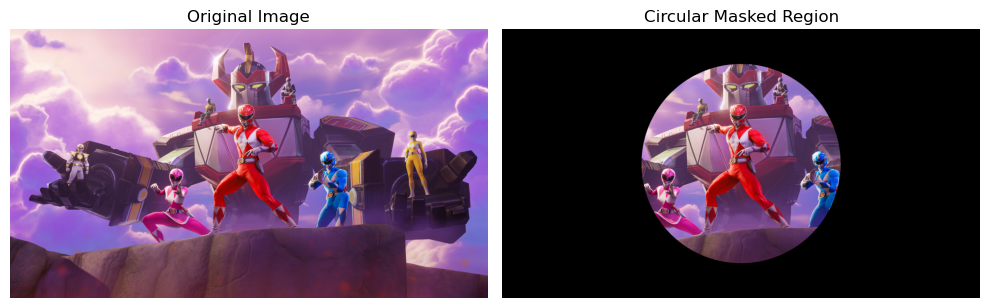

In [11]:
mask = np.zeros(gray.shape, dtype=np.uint8)
cv2.circle(mask,(gray.shape[1] // 2, gray.shape[0] // 2),800, 300, -1)
masked_image = cv2.bitwise_and(color_img, color_img, mask=mask)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(color_img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(masked_image, cv2.COLOR_BGR2RGB))
plt.title("Circular Masked Region")
plt.axis("off")

plt.tight_layout()
plt.show()

## 2.3 Grayscale & Per-Channel Colour Histograms

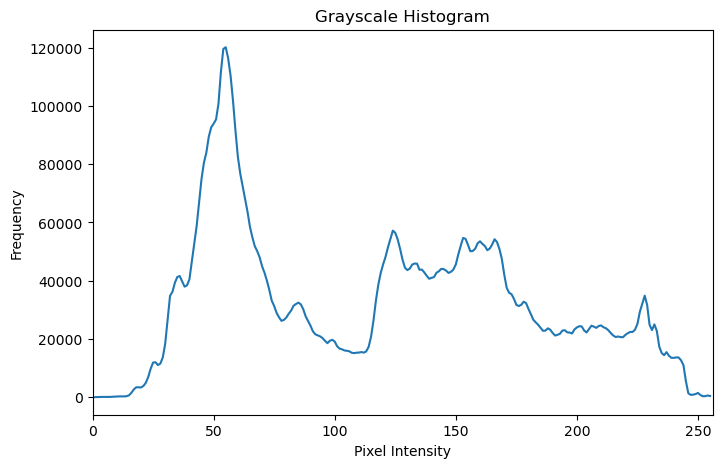

In [12]:
# Grayscale histogram
gray_hist = cv2.calcHist([gray],[0],None,[256],[0, 256])

plt.figure(figsize=(8, 5))
plt.plot(gray_hist)
plt.title("Grayscale Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 256])
plt.show()

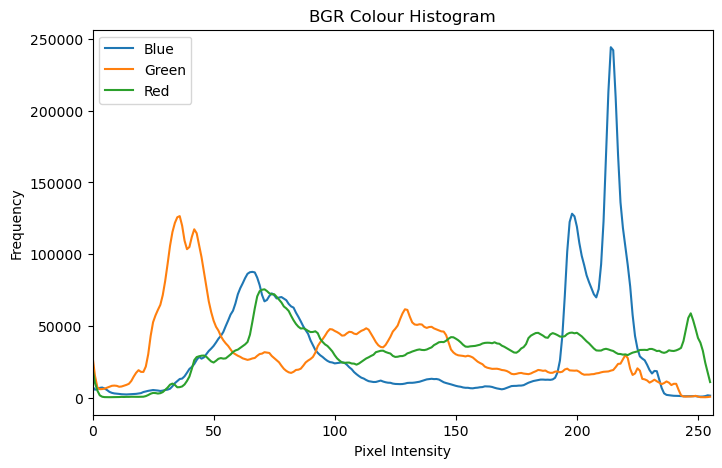

In [13]:
# Calculate B, G, R histograms
blue_hist = cv2.calcHist([color_img], [0], None, [256], [0, 256])
green_hist = cv2.calcHist([color_img], [1], None, [256], [0, 256])
red_hist = cv2.calcHist([color_img], [2], None, [256], [0, 256])

plt.figure(figsize=(8, 5))

plt.plot(blue_hist, label="Blue")
plt.plot(green_hist, label="Green")
plt.plot(red_hist, label="Red")

plt.title("BGR Colour Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 256])
plt.legend()
plt.show()

## 2.4 Brightness & Contrast Adjustment


In [14]:
bright_img = cv2.convertScaleAbs(color_img,alpha=1.5,beta=30)
dark_img = cv2.convertScaleAbs(color_img,alpha=0.7,beta=-30)

original_gray = cv2.cvtColor(color_img, cv2.COLOR_BGR2GRAY)
bright_gray = cv2.cvtColor(bright_img, cv2.COLOR_BGR2GRAY)
dark_gray = cv2.cvtColor(dark_img, cv2.COLOR_BGR2GRAY)

hist_original = cv2.calcHist([original_gray],[0],None,[256],[0,256])

hist_bright = cv2.calcHist([bright_gray],[0],None,[256],[0,256])

hist_dark = cv2.calcHist([dark_gray],[0],None,[256],[0,256])

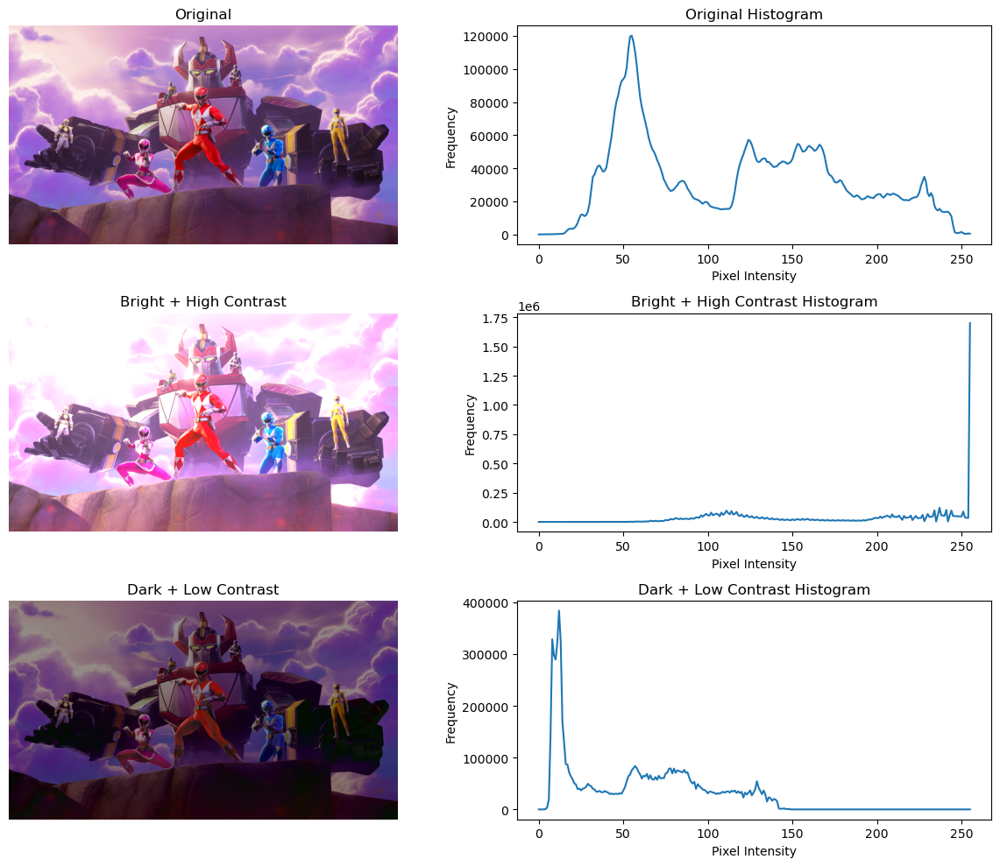

In [15]:
plt.figure(figsize=(12, 10))

# Original
plt.subplot(3, 2, 1)
plt.imshow(cv2.cvtColor(color_img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

plt.subplot(3, 2, 2)
plt.plot(hist_original)
plt.title("Original Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

# Bright + high contrast
plt.subplot(3, 2, 3)
plt.imshow(cv2.cvtColor(bright_img, cv2.COLOR_BGR2RGB))
plt.title("Bright + High Contrast")
plt.axis("off")

plt.subplot(3, 2, 4)
plt.plot(hist_bright)
plt.title("Bright + High Contrast Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

# Dark + low contrast
plt.subplot(3, 2, 5)
plt.imshow(cv2.cvtColor(dark_img, cv2.COLOR_BGR2RGB))
plt.title("Dark + Low Contrast")
plt.axis("off")

plt.subplot(3, 2, 6)
plt.plot(hist_dark)
plt.title("Dark + Low Contrast Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

## 2.5 explanation — one line each

### Alpha (α): Controls contrast by stretching or compressing the histogram.
### Beta (β): Controls brightness by shifting the histogram left or right.
### Narrow histogram: Indicates low contrast.
### Clipped histogram: Indicates overexposure or underexposure.

# Task 3

## 3.1 Load the YuNet Face Detector


In [16]:
# Load the YuNet model
model_path = "data/models/face_detection_yunet_2023mar.onnx"

img_h, img_w = color_img.shape[:2]

detector = cv2.FaceDetectorYN_create(
    model_path,
    "",
    (img_w, img_h),
    score_threshold=0.9
)

# Set input image size
detector.setInputSize((img_w, img_h))

print("YuNet Face Detector Loaded Successfully")

YuNet Face Detector Loaded Successfully


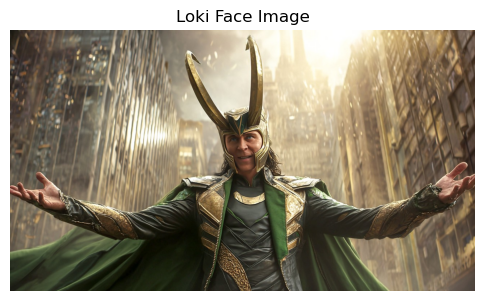

In [17]:
face_img = cv2.imread("data/images/loki.jpg")
show(face_img,"Loki Face Image")

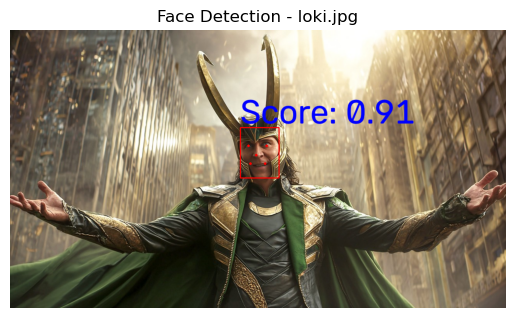

In [18]:
def detect_and_draw(image_path, detector):
    img = cv2.imread(image_path, cv2.IMREAD_COLOR)
    height = img.shape[0]
    width = img.shape[1]

    detector.setInputSize((width, height))
    result, faces = detector.detect(img)

    if faces is not None:
        for face in faces:
            x = int(face[0])
            y = int(face[1])
            w = int(face[2])
            h = int(face[3])
            score = face[14]

            cv2.rectangle(img, (x, y), (x + w, y + h), (0, 0, 255), 2)

            for i in range(5):
                landmark_x = int(face[4 + i * 2])
                landmark_y = int(face[4 + i * 2 + 1])
                cv2.circle(img, (landmark_x, landmark_y), 2, (0, 0, 255), 2)

            # Write the confidence score
            text = "Score: " + str(round(score, 2))
            cv2.putText(img, text, (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 3, (255,0, 0), 1)

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img_rgb

result1 = detect_and_draw("data/images/loki.jpg", detector)
plt.imshow(result1)
plt.title("Face Detection - loki.jpg")
plt.axis("off")
plt.show()

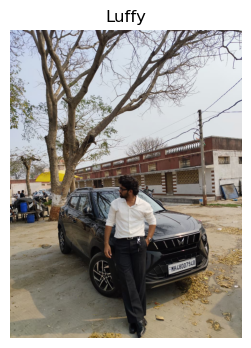

In [38]:
face_img2= cv2.imread("data/images/yash.jpeg")
show(face_img2,"Luffy")

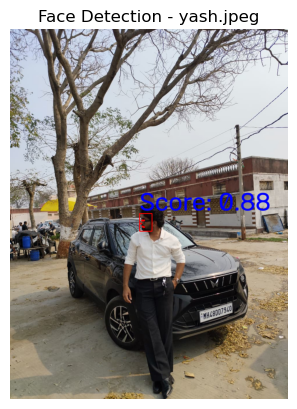

In [39]:
result3 = detect_and_draw("data/images/yash.jpeg",detector)
plt.imshow(result3)
plt.title("Face Detection - yash.jpeg")
plt.axis("off")
plt.show()

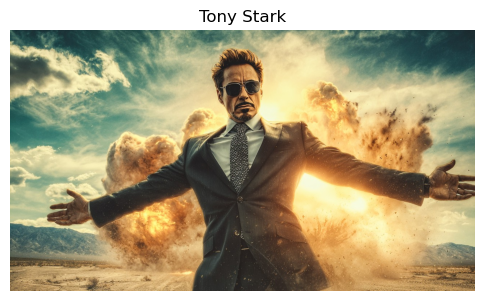

In [20]:
face_img3 = cv2.imread("data/images/tony.jpg")
show(face_img3,"Tony Stark")

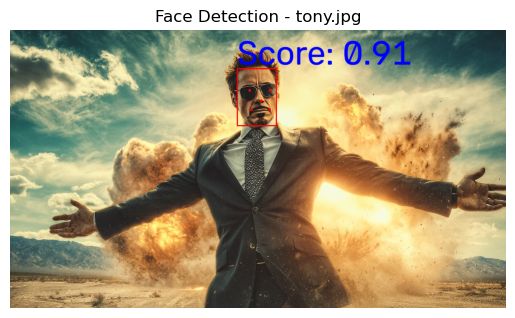

In [21]:
result3 = detect_and_draw("data/images/tony.jpg",detector)
plt.imshow(result3)
plt.title("Face Detection - tony.jpg")
plt.axis("off")
plt.show()

## 3.3 Real time detection on webcam

In [22]:
import time

# Start webcam
cap = cv2.VideoCapture(0)

# FPS calculation
prev_time = time.time()

while True:

    # Read webcam frame
    ret, frame = cap.read()

    if not ret:
        print("Unable to read webcam")
        break

    # Get frame size
    h, w = frame.shape[:2]

    # IMPORTANT: Match YuNet input size with webcam frame
    detector.setInputSize((w, h))

    # Detect faces
    _, faces = detector.detect(frame)

    # Draw detected faces
    if faces is not None:

        for face in faces:

            # Face bounding box
            x, y, fw, fh = face[:4].astype(int)

            # Confidence score
            score = face[-1]

            # Draw bounding box
            cv2.rectangle(
                frame,
                (x, y),
                (x + fw, y + fh),
                (0, 255, 0),
                2
            )

            # Display confidence
            cv2.putText(
                frame,
                f"Score: {score:.2f}",
                (x, y - 10),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255, 0, 0),
                2
            )

            # Get 5 facial landmarks
            landmarks = face[4:14].reshape(5, 2).astype(int)

            # Draw landmarks
            for px, py in landmarks:
                cv2.circle(
                    frame,
                    (px, py),
                    3,
                    (0, 255, 255),
                    -1
                )

    # Calculate FPS
    current_time = time.time()
    fps = 1 / (current_time - prev_time)
    prev_time = current_time

    # Display FPS
    cv2.putText(
        frame,
        f"FPS: {fps:.1f}",
        (10, 30),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2
    )

    # Display webcam
    cv2.imshow("YuNet Real-Time Face Detection", frame)

    # Press Q to quit
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

# Release webcam
cap.release()
cv2.destroyAllWindows()

## 3.4 Score-Threshold Experiment

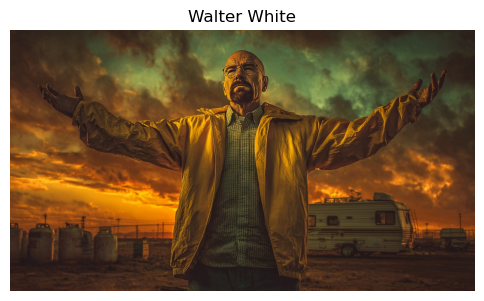

In [23]:
face_img4 = cv2.imread("data/images/walter.jpg")
show(face_img4,"Walter White")

In [24]:
# Test different score thresholds
thresholds = [0.5, 0.7, 0.9]

for threshold in thresholds:

    # Create detector with current threshold
    detector.setScoreThreshold(threshold)

    # Set image size
    h, w = face_img.shape[:2]
    detector.setInputSize((w, h))

    # Detect faces
    _, faces = detector.detect(face_img4)

    # Count faces
    count = 0 if faces is None else len(faces)

    print(f"Threshold: {threshold} | Detected Faces: {count}")

Threshold: 0.5 | Detected Faces: 1
Threshold: 0.7 | Detected Faces: 1
Threshold: 0.9 | Detected Faces: 0


In [25]:
detector.setScoreThreshold(0.7)

# Set input size
h, w = face_img.shape[:2]
detector.setInputSize((w, h))

# Detect faces
_, faces = detector.detect(face_img4)

# Make a copy for privacy blur
blurred_img = face_img4.copy()

# Blur detected face regions
if faces is not None:

    for face in faces:

        x, y, fw, fh = face[:4].astype(int)

        # Make sure coordinates stay inside image
        x1 = max(0, x)
        y1 = max(0, y)
        x2 = min(w, x + fw)
        y2 = min(h, y + fh)

        # Extract face region
        face_region = blurred_img[y1:y2, x1:x2]

        # Apply Gaussian blur
        blurred_img[y1:y2, x1:x2] = cv2.GaussianBlur(
            face_region,
            (51, 51),
            0)

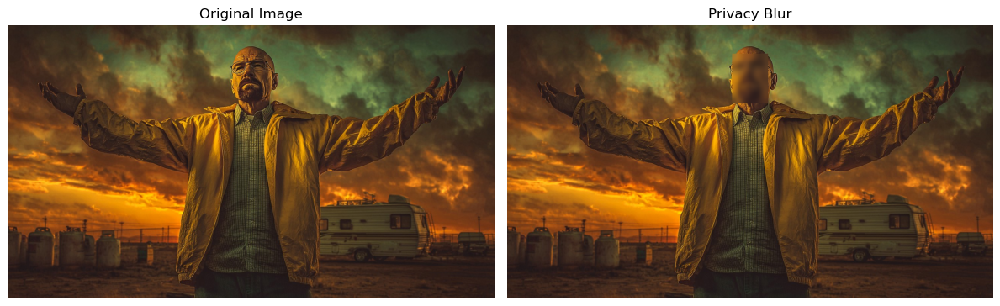

In [26]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(face_img4, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(blurred_img, cv2.COLOR_BGR2RGB))
plt.title("Privacy Blur")
plt.axis("off")

plt.tight_layout()
plt.show()

## 3.5 WHY YuNet

- **YuNet:** A compact CNN-based face detector for real-time detection.
- **Landmarks:** Detects 5 facial landmark points.
- **Confidence Score:** Shows how confident the detector is.
- **Low Threshold:** Detects more faces but may increase false positives.
- **High Threshold:** More selective but may miss some faces.

# Task 4


## 4.1 Load pretrained YOLOv8 & run on static images


image 1/1 c:\Users\patel\OneDrive\Desktop\R&W\Deep Learning\PR 3\data\images\objs.png: 448x640 4 persons, 1 bicycle, 5 cars, 1 motorcycle, 1 airplane, 2 buss, 1 train, 3 benchs, 3 birds, 2 dogs, 3 elephants, 1 giraffe, 1 sports ball, 192.0ms
Speed: 19.2ms preprocess, 192.0ms inference, 17.8ms postprocess per image at shape (1, 3, 448, 640)


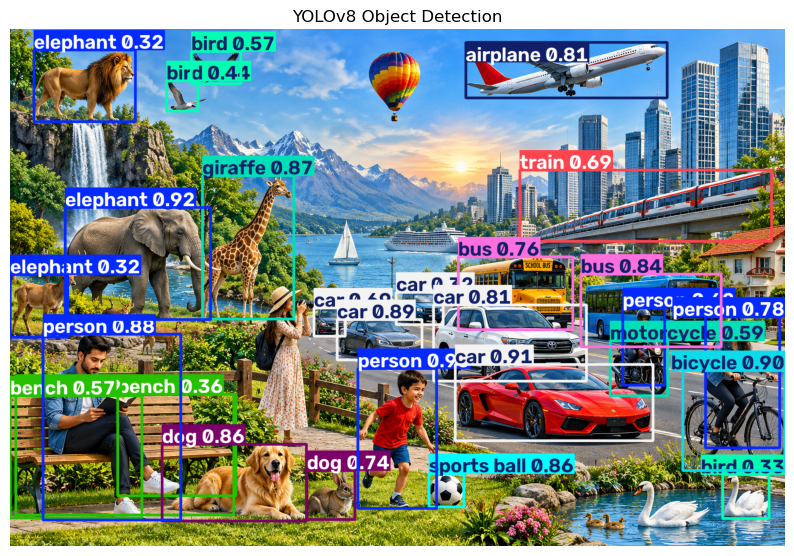

In [27]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# Load YOLOv8 Nano model
model = YOLO("yolov8n.pt")

# Image path
image_path = "data/images/objs.png"

# Run YOLO detection
results = model(image_path)

# Get annotated image
output = results[0].plot()

# Convert BGR to RGB
output = cv2.cvtColor(output, cv2.COLOR_BGR2RGB)

# Display result
plt.figure(figsize=(10, 7))
plt.imshow(output)
plt.title("YOLOv8 Object Detection")
plt.axis("off")
plt.show()


image 1/1 c:\Users\patel\OneDrive\Desktop\R&W\Deep Learning\PR 3\data\images\yash2.jpeg: 640x480 1 person, 1 car, 102.2ms
Speed: 5.2ms preprocess, 102.2ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 480)


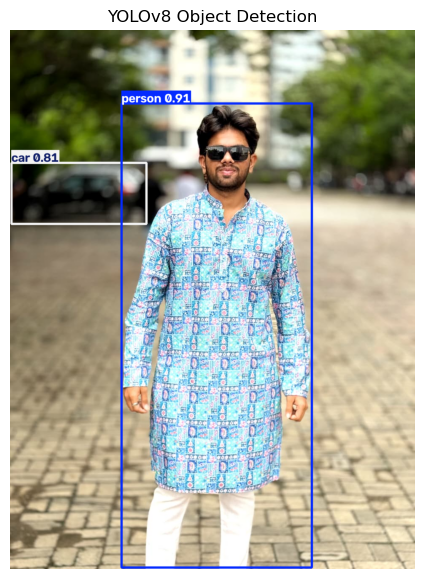

In [40]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# Load YOLOv8 Nano model
model = YOLO("yolov8n.pt")

# Image path
image_path = "data/images/yash2.jpeg"

# Run YOLO detection
results = model(image_path)

# Get annotated image
output = results[0].plot()

# Convert BGR to RGB
output = cv2.cvtColor(output, cv2.COLOR_BGR2RGB)

# Display result
plt.figure(figsize=(10, 7))
plt.imshow(output)
plt.title("YOLOv8 Object Detection")
plt.axis("off")
plt.show()

In [28]:
cap = cv2.VideoCapture(0)

prev_time = time.time()

while True:

    # Read frame
    ret, frame = cap.read()

    if not ret:
        print("Unable to read webcam")
        break

    # Run YOLO detection
    results = model(frame, verbose=False)

    # Draw detections
    output = results[0].plot()

    # Calculate FPS
    current_time = time.time()
    fps = 1 / (current_time - prev_time)
    prev_time = current_time

    # Display FPS
    cv2.putText(
        output,
        f"FPS: {fps:.1f}",
        (10, 30),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2
    )

    # Display webcam
    cv2.imshow("YOLOv8 Real-Time Object Detection", output)

    # Press Q to quit
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

# Release webcam
cap.release()
cv2.destroyAllWindows()

## 4.3 Confidence & IoU Threshold Tuning

In [29]:
conf_values = [0.25, 0.5, 0.75]

for conf in conf_values:
    
    results = model(
        image_path,
        conf=conf,
        verbose=False
    )

    count = len(results[0].boxes)

    print(f"Confidence: {conf} | Detected Boxes: {count}")

Confidence: 0.25 | Detected Boxes: 28
Confidence: 0.5 | Detected Boxes: 21
Confidence: 0.75 | Detected Boxes: 14


In [30]:
iou_values = [0.3, 0.5, 0.7]

for iou in iou_values:
    
    results = model(
        image_path,
        conf=0.25,
        iou=iou,
        verbose=False
    )

    count = len(results[0].boxes)

    print(f"IoU: {iou} | Detected Boxes: {count}")

IoU: 0.3 | Detected Boxes: 27
IoU: 0.5 | Detected Boxes: 27
IoU: 0.7 | Detected Boxes: 28


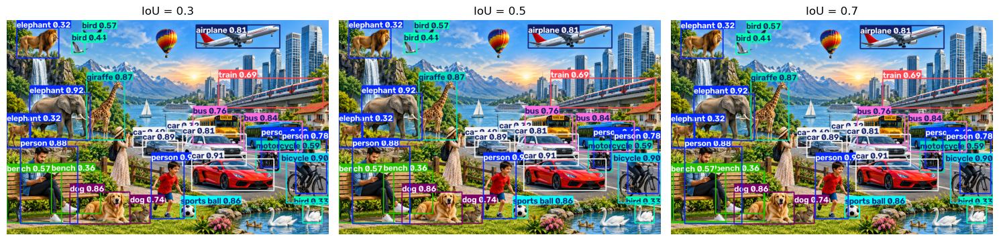

In [31]:
plt.figure(figsize=(15, 5))

for i, iou in enumerate([0.3, 0.5, 0.7]):

    results = model(
        image_path,
        conf=0.25,
        iou=iou,
        verbose=False
    )

    output = results[0].plot()
    output = cv2.cvtColor(output, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 3, i + 1)
    plt.imshow(output)
    plt.title(f"IoU = {iou}")
    plt.axis("off")

plt.tight_layout()
plt.show()

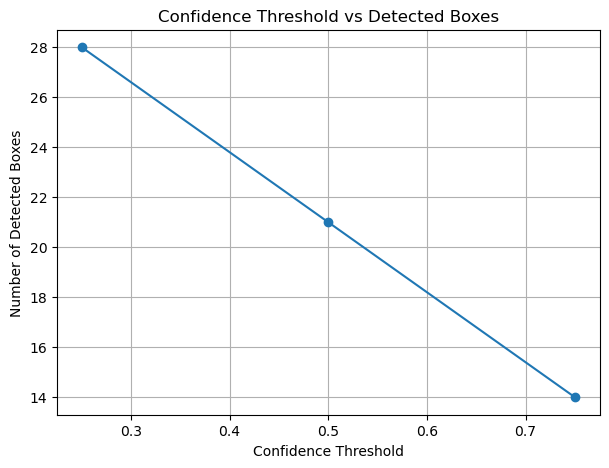

In [32]:
conf_values = [0.25, 0.5, 0.75]
conf_counts = []

for conf in conf_values:
    results = model(
        image_path,
        conf=conf,
        verbose=False
    )
    
    conf_counts.append(len(results[0].boxes))

plt.figure(figsize=(7, 5))
plt.plot(conf_values, conf_counts, marker="o")
plt.xlabel("Confidence Threshold")
plt.ylabel("Number of Detected Boxes")
plt.title("Confidence Threshold vs Detected Boxes")
plt.grid(True)
plt.show()

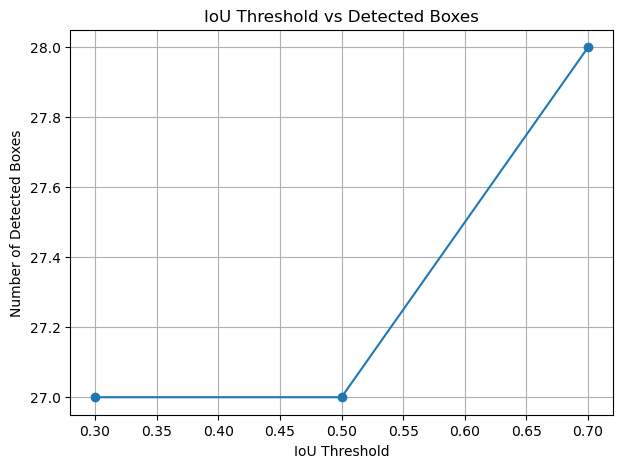

In [33]:
iou_values = [0.3, 0.5, 0.7]
iou_counts = []

for iou in iou_values:
    results = model(
        image_path,
        conf=0.25,
        iou=iou,
        verbose=False
    )
    
    iou_counts.append(len(results[0].boxes))

plt.figure(figsize=(7, 5))
plt.plot(iou_values, iou_counts, marker="o")
plt.xlabel("IoU Threshold")
plt.ylabel("Number of Detected Boxes")
plt.title("IoU Threshold vs Detected Boxes")
plt.grid(True)
plt.show()

## 4.4 Per-Class Detection Summary

Per-Class Detection Counts:
elephant: 3
car: 7
person: 7
bicycle: 1
giraffe: 1
dog: 2
sports ball: 1
bus: 3
airplane: 1
train: 1
motorcycle: 1
bird: 3
bench: 3
truck: 1


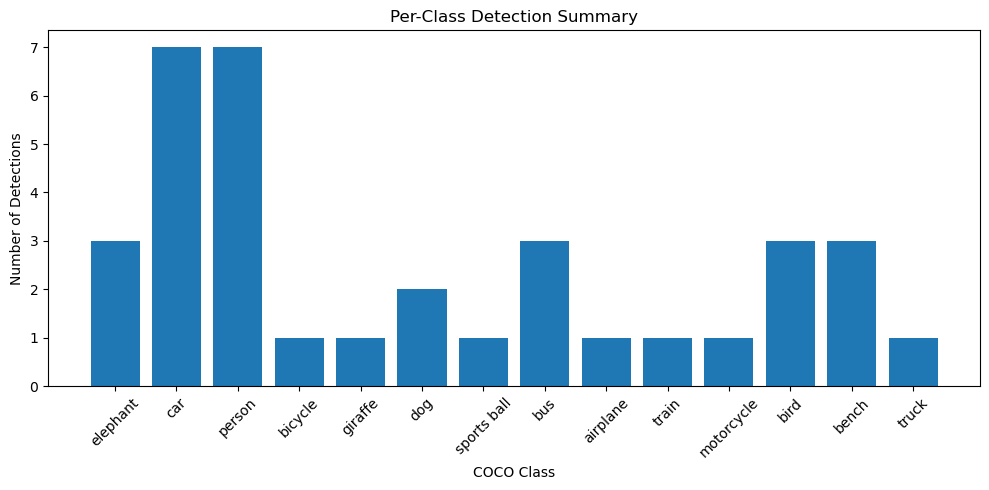

In [34]:
from collections import Counter
import matplotlib.pyplot as plt

# Test images
image_paths = [
    "data/images/objs.png",
    "data/images/loki.jpg",
    "data/images/walter.jpg",
    "data/images/cars.jpeg"
]

class_counts = Counter()

for path in image_paths:
    results = model(path, verbose=False)

    for cls_id in results[0].boxes.cls.tolist():
        class_name = model.names[int(cls_id)]
        class_counts[class_name] += 1

# Display counts
print("Per-Class Detection Counts:")
for name, count in class_counts.items():
    print(f"{name}: {count}")

# Bar chart
plt.figure(figsize=(10, 5))
plt.bar(class_counts.keys(), class_counts.values())
plt.xlabel("COCO Class")
plt.ylabel("Number of Detections")
plt.title("Per-Class Detection Summary")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4.5 Why YOLO Generalises
YOLO is a fast, single-stage detector that predicts object boxes and classes in one pass. NMS removes duplicate boxes.

**YOLOv8n**: Smallest and fastest; good for real-time use.
**YOLOv8s/m/l/x**: Larger and more accurate but slower.
**80 COCO classes**: One pretrained model can detect all classes using shared learned features.

# Task 5

## 5.1 Integrated Pipeline


In [35]:
cap = cv2.VideoCapture(0)

while True:
    ret, frame = cap.read()
    if not ret:
        break

    h, w = frame.shape[:2]

    # ---------------- YuNet Face Detection ----------------
    detector.setInputSize((w, h))
    _, faces = detector.detect(frame)

    if faces is not None:
        for face in faces:
            x, y, fw, fh = face[:4].astype(int)
            score = face[-1]

            # Green face box
            cv2.rectangle(frame, (x, y), (x + fw, y + fh),
                          (0, 255, 0), 2)

            cv2.putText(frame, f"Face {score:.2f}",
                        (x, y - 8),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5,
                        (0, 255, 0), 2)

    # ---------------- YOLOv8 Object Detection ----------------
    results = model(frame, verbose=False)

    for box, cls, conf in zip(
        results[0].boxes.xyxy.cpu().numpy(),
        results[0].boxes.cls.cpu().numpy(),
        results[0].boxes.conf.cpu().numpy()
    ):
        x1, y1, x2, y2 = map(int, box)

        label = f"{model.names[int(cls)]} {conf:.2f}"

        # Red object box
        cv2.rectangle(frame, (x1, y1), (x2, y2),
                      (0, 0, 255), 2)

        cv2.putText(frame, label,
                    (x1, y1 - 8),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5,
                    (0, 0, 255), 2)

    cv2.imshow("YuNet + YOLOv8 Integrated Pipeline", frame)

    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cap.release()
cv2.destroyAllWindows()

## 5.2 Morphological Pre-Cleaning



0: 448x640 4 persons, 1 bicycle, 5 cars, 1 motorcycle, 1 airplane, 2 buss, 1 train, 3 benchs, 3 birds, 2 dogs, 3 elephants, 1 giraffe, 1 sports ball, 56.0ms
Speed: 2.4ms preprocess, 56.0ms inference, 1.0ms postprocess per image at shape (1, 3, 448, 640)

0: 448x640 4 persons, 1 bicycle, 5 cars, 1 motorcycle, 1 airplane, 2 buss, 1 train, 2 benchs, 2 birds, 2 dogs, 3 elephants, 1 giraffe, 1 sports ball, 51.4ms
Speed: 2.3ms preprocess, 51.4ms inference, 1.3ms postprocess per image at shape (1, 3, 448, 640)
Boxes detected (noisy): 28
Boxes detected (cleaned): 26


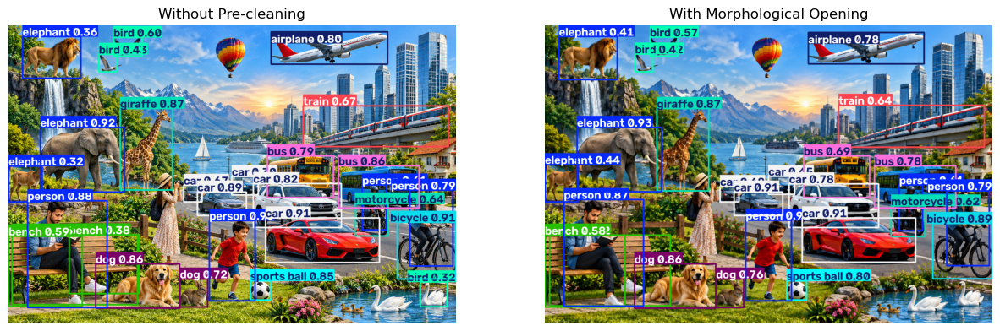

In [36]:
img_noisy_test = cv2.imread("data/images/objs.png", cv2.IMREAD_COLOR)

noisy_test = img_noisy_test.copy()
height = noisy_test.shape[0]
width = noisy_test.shape[1]
num_noise_pixels = int(0.01 * height * width)

for i in range(num_noise_pixels):
    row = np.random.randint(0, height)
    col = np.random.randint(0, width)
    channel = np.random.randint(0, 3)
    noisy_test[row, col, channel] = 255

kernel_small = np.ones((3, 3), np.uint8)
cleaned_test = cv2.morphologyEx(noisy_test, cv2.MORPH_OPEN, kernel_small)

results_noisy = model(noisy_test)
results_cleaned = model(cleaned_test)

annotated_noisy = results_noisy[0].plot()
annotated_cleaned = results_cleaned[0].plot()

annotated_noisy_rgb = cv2.cvtColor(annotated_noisy, cv2.COLOR_BGR2RGB)
annotated_cleaned_rgb = cv2.cvtColor(annotated_cleaned, cv2.COLOR_BGR2RGB)

print("Boxes detected (noisy):", len(results_noisy[0].boxes))
print("Boxes detected (cleaned):", len(results_cleaned[0].boxes))

plt.figure(figsize=(15, 7))

plt.subplot(1, 2, 1)
plt.imshow(annotated_noisy_rgb)
plt.title("Without Pre-cleaning")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(annotated_cleaned_rgb)
plt.title("With Morphological Opening")
plt.axis("off")

plt.show()

## 5.3 FPS Benchmarking


Frames captured: 100
YuNet Face Detection FPS : 37.86
YOLOv8 Detection FPS    : 14.81
Combined Pipeline FPS    : 10.15


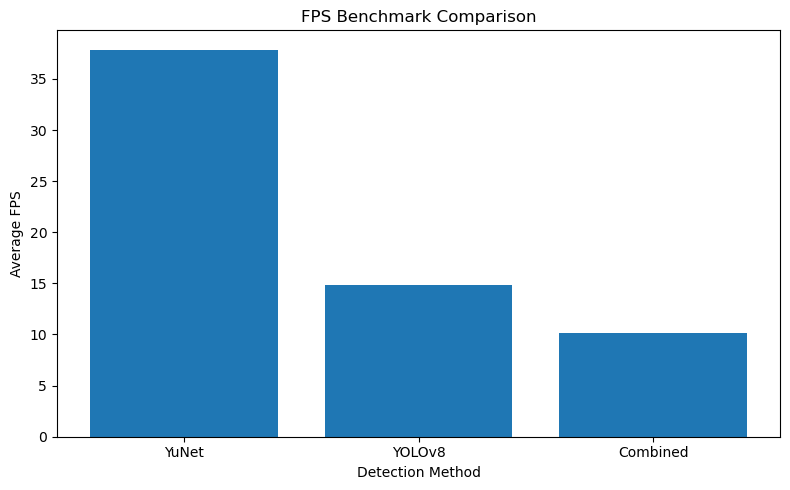

In [37]:
# Capture the same 100 frames
cap = cv2.VideoCapture(0)
frames = []

while len(frames) < 100:
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(frame.copy())

cap.release()

print("Frames captured:", len(frames))


# Benchmark function
def benchmark(mode):
    times = []

    for frame in frames:
        start = time.perf_counter()

        if mode == "face":
            h, w = frame.shape[:2]
            detector.setInputSize((w, h))
            detector.detect(frame)

        elif mode == "yolo":
            model(frame, verbose=False)

        elif mode == "combined":
            h, w = frame.shape[:2]
            detector.setInputSize((w, h))
            detector.detect(frame)
            model(frame, verbose=False)

        times.append(time.perf_counter() - start)

    average_time = sum(times) / len(times)
    return 1 / average_time


# Calculate FPS
face_fps = benchmark("face")
yolo_fps = benchmark("yolo")
combined_fps = benchmark("combined")

print(f"YuNet Face Detection FPS : {face_fps:.2f}")
print(f"YOLOv8 Detection FPS    : {yolo_fps:.2f}")
print(f"Combined Pipeline FPS    : {combined_fps:.2f}")


# Plot FPS comparison
methods = ["YuNet", "YOLOv8", "Combined"]
fps_values = [face_fps, yolo_fps, combined_fps]

plt.figure(figsize=(8, 5))
plt.bar(methods, fps_values)
plt.xlabel("Detection Method")
plt.ylabel("Average FPS")
plt.title("FPS Benchmark Comparison")
plt.tight_layout()
plt.show()

## 5.4 Final Comparison Table


| Technique | Type | What It Detects | Lighting Robustness | Approx. FPS | Best Use Case |
|---|---|---|---|---|---|
| Morphology | Classical | Shapes and image noise | Depends on preprocessing | Very Fast | Noise removal |
| Bitwise / Histograms | Classical | Masks and pixel distributions | Depends on image | Very Fast | Image analysis and masking |
| YuNet | Deep Learning | Faces | Good | **Use your measured FPS** | Real-time face detection |
| YOLOv8n | Deep Learning | 80 COCO object classes | Good | **Use your measured FPS** | Real-time object detection |

## 5.5 Reflection

The combination of classical image processing, YuNet, and YOLOv8
provides a practical real-time computer vision pipeline.

For low-power edge devices, lightweight models such as YuNet and YOLOv8n
are suitable because they require less computation.

For cloud servers, larger models can be used when higher accuracy is
required and more computational resources are available.